# Hybrid Head+LoRA Fine-tuning: Training Inspection & Evaluation

**Run:** `fine_tuned_hybrid_freeze2_2026-02-28_16-26-59`  
**Strategy:** Phase 1 — head-only (trunk frozen, 2 epochs) → Phase 2 — head + LoRA rank=8 (8 epochs)  
**Signal:** CUT&Tag (ZHY-250227-1), mm10 mouse genome  
**Best loss:** 0.000138 (saved at `best_checkpoint/model/`)  
**NOTE:** Checkpoint is already portable numpy — no conversion step required.

## 1. Setup & Imports

In [1]:
import os
import sys
import json
import warnings
warnings.filterwarnings('ignore')

# ── Single-GPU inference mode ───────────────────────────────────────────────
# Must be set before any JAX/CUDA import.
# Avoids NCCL dual-instance deadlock (no LD_PRELOAD in notebooks).
# The checkpoint was saved with jax.device_get() during training, so it is
# already plain numpy — no 8-GPU NamedSharding to reconstruct.
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

sys.path.insert(0, '/home/ray/alphagenome_research')
sys.path.insert(0, '/home/ray/AG_Finetune')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats

import pyBigWig
import pyfaidx

# ── JAX persistent compilation cache ───────────────────────────────────────
import jax
jax.config.update('jax_compilation_cache_dir',
                  '/home/ray/AG_Finetune/.jax_cache')
jax.config.update('jax_persistent_cache_min_compile_time_secs', 5)
import jax.numpy as jnp

print(f"JAX version  : {jax.__version__}")
print(f"JAX devices  : {jax.devices()}")
print(f"JAX cache    : /home/ray/AG_Finetune/.jax_cache")
print(f"Matplotlib   : {matplotlib.__version__}")

# ── Paths ──────────────────────────────────────────────────────────────────
RUN_DIR = '/home/ray/AG_Finetune/checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59'

# Checkpoint saved with jax.device_get() → plain numpy, no device sharding.
# Load directly without conversion step.
CHECKPOINT_DIR  = os.path.join(RUN_DIR, 'best_checkpoint', 'model')

METRICS_CSV     = os.path.join(RUN_DIR, 'metrics.csv')
TRAINING_CONFIG = os.path.join(RUN_DIR, 'training_config.json')
FASTA_PATH      = '/home/ray/AG_Finetune/data/resources/mm10.fa'
SIGNAL_PATH     = (
    '/home/ray/AG_Finetune/data/CUTTag/ZHY-250227-1/'
    'ZHY-250227-1_ACTGCATATAAGGCGA/alignment/bigwig/'
    'ZHY-250227-1_ACTGCATATAAGGCGA_bowtie2.chrombpnet_reads_to_bw_unstranded.bw'
)
WINDOW_SIZE     = 131_072   # 2^17 bp
ORGANISM_ID     = 1         # mouse

print(f"\nRun dir       : {RUN_DIR}")
print(f"Checkpoint    : {CHECKPOINT_DIR}")
print(f"Metrics CSV   : {METRICS_CSV}")
print(f"Signal BigWig : {SIGNAL_PATH}")
print(f"FASTA         : {FASTA_PATH}")
print(f"Checkpoint exists: {os.path.exists(CHECKPOINT_DIR)}")

JAX version  : 0.9.0
JAX devices  : [CudaDevice(id=0)]
JAX cache    : /home/ray/AG_Finetune/.jax_cache
Matplotlib   : 3.10.8

Run dir       : /home/ray/AG_Finetune/checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59
Checkpoint    : /home/ray/AG_Finetune/checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59/best_checkpoint/model
Metrics CSV   : /home/ray/AG_Finetune/checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59/metrics.csv
Signal BigWig : /home/ray/AG_Finetune/data/CUTTag/ZHY-250227-1/ZHY-250227-1_ACTGCATATAAGGCGA/alignment/bigwig/ZHY-250227-1_ACTGCATATAAGGCGA_bowtie2.chrombpnet_reads_to_bw_unstranded.bw
FASTA         : /home/ray/AG_Finetune/data/resources/mm10.fa
Checkpoint exists: True


## 2. Training Run Summary

In [2]:
# ── Load training_config.json ───────────────────────────────────────────────
with open(TRAINING_CONFIG) as f:
    cfg = json.load(f)

print("=" * 60)
print("TRAINING RUN SUMMARY")
print("=" * 60)
for k, v in cfg.items():
    print(f"  {k:<25} : {v}")

# ── Checkpoint directory listing ────────────────────────────────────────────
print("\n" + "=" * 60)
print("CHECKPOINT DIRECTORY CONTENTS")
print("=" * 60)
for entry in sorted(os.listdir(RUN_DIR)):
    full = os.path.join(RUN_DIR, entry)
    marker = "/" if os.path.isdir(full) else ""
    print(f"  {entry}{marker}")

TRAINING RUN SUMMARY
  strategy                  : hybrid
  freeze_epochs             : 2
  lora_rank                 : 8
  lora_alpha                : 16.0
  checkpoint_path           : /home/ray/AG_Finetune/checkpoints/pre_trained/alphagenome-all-folds
  precision_policy          : params=float32,compute=float32,output=float32
  learning_rate             : 5e-4
  epochs                    : 10
  batch_size                : 8
  window_size               : 131072
  best_loss                 : 0.0001382834030664526
  signal_format             : BigWig

CHECKPOINT DIRECTORY CONTENTS
  best_checkpoint/
  config_bigwig_hybrid.yaml
  epoch_001/
  epoch_002/
  epoch_003/
  epoch_004/
  epoch_005/
  epoch_006/
  epoch_007/
  epoch_008/
  epoch_009/
  epoch_010/
  metrics.csv
  stderr.log
  train.log
  training_config.json


## 3. Load Training Metrics

In [3]:
df = pd.read_csv(METRICS_CSV, parse_dates=['timestamp'])

# Drop skipped steps
df_clean = df[~df['skipped']].copy().reset_index(drop=True)
df_clean['global_step'] = df_clean.index + 1

# Rolling average
ROLL_WIN = 50
df_clean['loss_rolling'] = df_clean['loss'].rolling(ROLL_WIN, min_periods=1).mean()

# Identify phase transition
lora_mask = df_clean['phase'] == 'lora'
transition_step = df_clean.loc[lora_mask, 'global_step'].iloc[0] if lora_mask.any() else None

# Per-epoch stats
epoch_stats = (df_clean.groupby(['epoch', 'phase'])['loss']
               .agg(['mean', 'min', 'median', 'std'])
               .reset_index())

print(f"Total steps    : {len(df_clean):,}")
print(f"Phase 'frozen' : {(df_clean['phase']=='frozen').sum():,} steps")
print(f"Phase 'lora'   : {(df_clean['phase']=='lora').sum():,} steps")
print(f"Transition at global step : {transition_step}")
print(f"Overall best loss         : {df_clean['loss'].min():.6f}")
print(f"\nPer-epoch statistics:")
print(epoch_stats.to_string(index=False, float_format='%.5f'))

Total steps    : 25,980
Phase 'frozen' : 5,196 steps
Phase 'lora'   : 20,784 steps
Transition at global step : 5197
Overall best loss         : 0.000012

Per-epoch statistics:
 epoch  phase    mean     min  median     std
     1 frozen 0.07479 0.00008 0.04269 0.16392
     2 frozen 0.03898 0.00006 0.03897 0.02039
     3   lora 0.03798 0.00001 0.03788 0.01996
     4   lora 0.03706 0.00001 0.03702 0.01949
     5   lora 0.03674 0.00001 0.03673 0.01932
     6   lora 0.03655 0.00001 0.03657 0.01920
     7   lora 0.03640 0.00001 0.03643 0.01911
     8   lora 0.03629 0.00001 0.03631 0.01905
     9   lora 0.03622 0.00001 0.03621 0.01901
    10   lora 0.03618 0.00001 0.03617 0.01898


## 4. Training Loss Curves

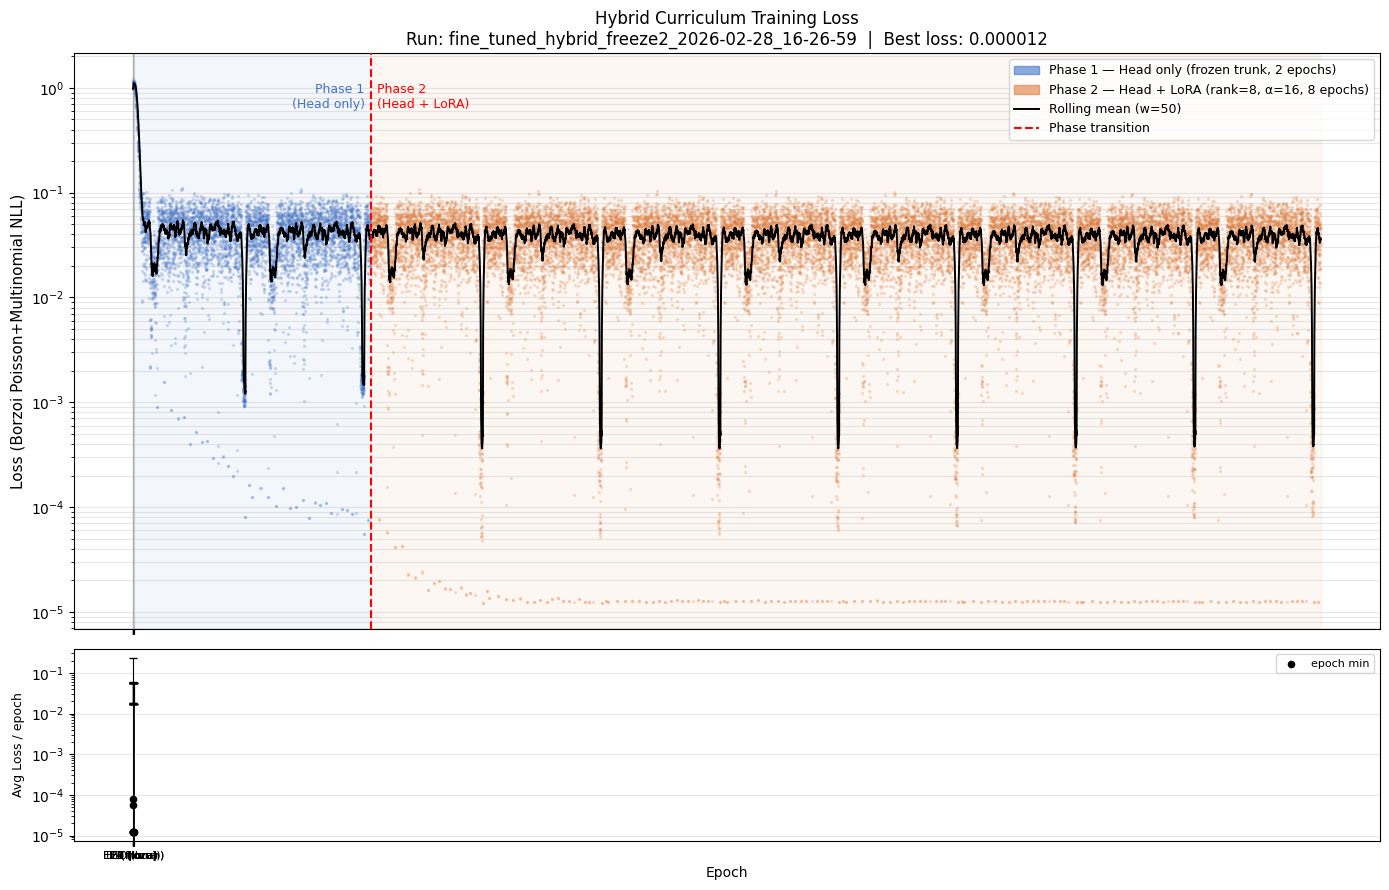

Saved → /home/ray/AG_Finetune/checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59/training_curve.png


In [4]:
PHASE_COLORS = {'frozen': '#4273c8', 'lora': '#e07b39'}

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1]})
ax_loss, ax_epoch = axes

# ── Top: per-step loss scatter + rolling mean ───────────────────────────────
for phase, grp in df_clean.groupby('phase', sort=False):
    ax_loss.scatter(grp['global_step'], grp['loss'],
                    s=2, alpha=0.18, color=PHASE_COLORS[phase], zorder=2)

ax_loss.plot(df_clean['global_step'], df_clean['loss_rolling'],
             color='k', lw=1.4, zorder=3, label=f'Rolling mean (w={ROLL_WIN})')

x_max = df_clean['global_step'].max()
ax_loss.axvspan(1, transition_step or x_max, alpha=0.06, color=PHASE_COLORS['frozen'])
if transition_step:
    ax_loss.axvspan(transition_step, x_max, alpha=0.06, color=PHASE_COLORS['lora'])
    ax_loss.axvline(transition_step, color='red', lw=1.5, linestyle='--',
                    zorder=4, label='Phase transition')
    ylim = ax_loss.get_ylim()
    ax_loss.text(transition_step + x_max * 0.005, ylim[1] * 0.88,
                 'Phase 2\n(Head + LoRA)', color='red', fontsize=9, va='top')
    ax_loss.text(transition_step - x_max * 0.005, ylim[1] * 0.88,
                 'Phase 1\n(Head only)', color=PHASE_COLORS['frozen'],
                 fontsize=9, va='top', ha='right')

legend_handles = [
    mpatches.Patch(color=PHASE_COLORS['frozen'], alpha=0.6,
                   label='Phase 1 — Head only (frozen trunk, 2 epochs)'),
    mpatches.Patch(color=PHASE_COLORS['lora'],   alpha=0.6,
                   label='Phase 2 — Head + LoRA (rank=8, α=16, 8 epochs)'),
]
handles2, labels2 = ax_loss.get_legend_handles_labels()
ax_loss.legend(handles=legend_handles + handles2, fontsize=9, loc='upper right')
ax_loss.set_ylabel('Loss (Borzoi Poisson+Multinomial NLL)', fontsize=11)
ax_loss.set_title(
    'Hybrid Curriculum Training Loss\n'
    f'Run: fine_tuned_hybrid_freeze2_2026-02-28_16-26-59  |  '
    f'Best loss: {df_clean["loss"].min():.6f}',
    fontsize=12)
ax_loss.set_yscale('log')
ax_loss.grid(True, which='both', alpha=0.3)

# ── Bottom: per-epoch average loss ─────────────────────────────────────────
for _, row in epoch_stats.iterrows():
    color = PHASE_COLORS[row['phase']]
    ax_epoch.bar(row['epoch'], row['mean'], color=color, alpha=0.7,
                 edgecolor='k', linewidth=0.5)
    ax_epoch.scatter(row['epoch'], row['min'], color='k', s=20, zorder=5,
                     label='epoch min' if row.name == 0 else '')
    ax_epoch.errorbar(row['epoch'], row['mean'], yerr=row['std'],
                      color='k', capsize=3, linewidth=0.8)

ax_epoch.set_xlabel('Epoch', fontsize=10)
ax_epoch.set_ylabel('Avg Loss / epoch', fontsize=9)
ax_epoch.set_xticks(epoch_stats['epoch'])
ax_epoch.set_xticklabels(
    [f"E{int(e)} ({p})" for e, p in zip(epoch_stats['epoch'], epoch_stats['phase'])],
    fontsize=8)
ax_epoch.grid(True, axis='y', alpha=0.3)
ax_epoch.set_yscale('log')
ax_epoch.legend(fontsize=8)

plt.tight_layout()
out = os.path.join(RUN_DIR, 'training_curve.png')
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {out}")

## 5. Step-level Loss Curves per Epoch

Zoom into each epoch independently to see intra-epoch loss dynamics.

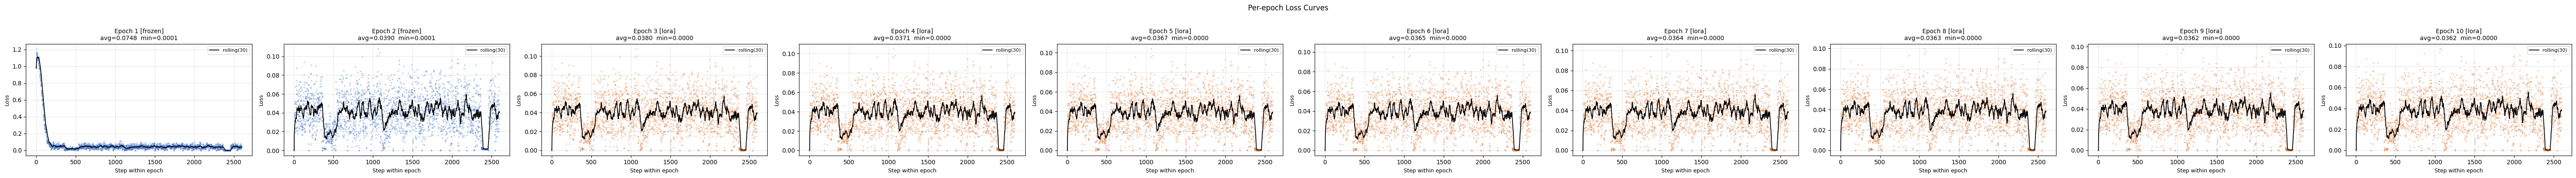

Saved → /home/ray/AG_Finetune/checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59/per_epoch_curves.png


In [5]:
epochs = sorted(df_clean['epoch'].unique())
n_epochs = len(epochs)

fig, axes = plt.subplots(1, n_epochs, figsize=(6 * n_epochs, 4), sharey=False)
if n_epochs == 1:
    axes = [axes]

for ax, ep in zip(axes, epochs):
    sub = df_clean[df_clean['epoch'] == ep].copy()
    phase = sub['phase'].iloc[0]
    color = PHASE_COLORS[phase]
    step_in_epoch = np.arange(1, len(sub) + 1)

    ax.scatter(step_in_epoch, sub['loss'].values,
               s=3, alpha=0.25, color=color)
    roll = sub['loss'].rolling(30, min_periods=1).mean().values
    ax.plot(step_in_epoch, roll, color='k', lw=1.3, label='rolling(30)')

    ax.set_title(f"Epoch {ep} [{phase}]\navg={sub['loss'].mean():.4f}  min={sub['loss'].min():.4f}",
                 fontsize=10)
    ax.set_xlabel('Step within epoch', fontsize=9)
    ax.set_ylabel('Loss', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle('Per-epoch Loss Curves', fontsize=12, y=1.02)
plt.tight_layout()
out = os.path.join(RUN_DIR, 'per_epoch_curves.png')
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {out}")

## 6. Load Fine-tuned Model

The checkpoint at `best_checkpoint/model/` was saved by the training script with `jax.device_get()`, making it plain numpy with no 8-GPU `NamedSharding`. It loads cleanly on a single GPU.

**Critical:** We must reconstruct the exact same `AlphaGenomeOutputMetadata` used during training (1 ATAC track). Using `metadata_lib.load(ORGANISM)` would give a 256-track head whose weights don't match the fine-tuned 1-track head.

In [6]:
import orbax.checkpoint as ocp
from alphagenome_research.model import dna_model
from alphagenome_research.model.metadata import metadata as metadata_lib
from alphagenome.models import dna_output

ORGANISM = dna_model.Organism.MUS_MUSCULUS

# ── Reconstruct the 1-track metadata used during training ──────────────────
# Must match tf_ft_hybrid.py lines 869-875 exactly.
track_df = pd.DataFrame([{
    'output_type': 'ATAC',
    'name': 'CUT&Tag',
    'strand': '.',
    'file_path': SIGNAL_PATH,
}])
fine_tune_metadata = metadata_lib.AlphaGenomeOutputMetadata(atac=track_df)

device = jax.devices()[0]

print(f"Loading checkpoint from: {CHECKPOINT_DIR}")
print(f"Device  : {device}")
print(f"Organism: {ORGANISM}")
print(f"ATAC tracks in metadata: {len(track_df)}")

model = dna_model.create(
    checkpoint_path=CHECKPOINT_DIR,
    organism_settings={
        ORGANISM: dna_model.OrganismSettings(
            metadata=fine_tune_metadata,
            fasta_path=FASTA_PATH,
        )
    },
    device=device,
)
print(f"\n✓ Model loaded successfully on {device}")

Loading checkpoint from: /home/ray/AG_Finetune/checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59/best_checkpoint/model
Device  : cuda:0
Organism: Organism.MUS_MUSCULUS
ATAC tracks in metadata: 1



✓ Model loaded successfully on cuda:0


## 7. Run Evaluation Script

Inference is handled by `scripts/evaluate.py` — a standalone script that flushes stdout immediately, handles XLA compilation outside the kernel, and exits cleanly.

**Run in a terminal:**
```bash
CUDA_VISIBLE_DEVICES=0 conda run -n alphagenome python scripts/evaluate.py \
    --run-dir checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59
```

The cell below launches it as a subprocess and streams its output here.  
All plots and `eval_metrics.csv` are written to the run directory.

In [7]:
import subprocess, sys, os

EVAL_SCRIPT = os.path.join(
    '/home/ray/AG_Finetune', 'scripts', 'evaluate.py')

cmd = [
    sys.executable, EVAL_SCRIPT,
    '--run-dir', RUN_DIR,
]

env = os.environ.copy()
env['CUDA_VISIBLE_DEVICES'] = '0'

print("Running:", ' '.join(cmd))
print('=' * 60, flush=True)

proc = subprocess.Popen(
    cmd,
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,          # line-buffered
)

for line in proc.stdout:
    print(line, end='', flush=True)

proc.wait()
rc = proc.returncode
print('=' * 60)
print(f"Exit code: {rc}")
if rc != 0:
    raise RuntimeError(f"evaluate.py failed with exit code {rc}")

Running: /home/ray/miniforge3/envs/alphagenome/bin/python /home/ray/AG_Finetune/scripts/evaluate.py --run-dir /home/ray/AG_Finetune/checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59
[env] CUDA_VISIBLE_DEVICES = 0

AlphaGenome Fine-tuned Evaluation
  Run dir    : /home/ray/AG_Finetune/checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59
  Checkpoint : /home/ray/AG_Finetune/checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59/best_checkpoint/model
  Signal     : /home/ray/AG_Finetune/data/CUTTag/ZHY-250227-1/ZHY-250227-1_ACTGCATATAAGGCGA/alignment/bigwig/ZHY-250227-1_ACTGCATATAAGGCGA_bowtie2.chrombpnet_reads_to_bw_unstranded.bw
  Test chroms: ['chr17', 'chr18', 'chr19']
  Windows    : 5 per chrom

  Training config:
    strategy              : hybrid
    freeze_epochs         : 2
    lora_rank             : 8
    lora_alpha            : 16.0
    checkpoint_path       : /home/ray/AG_Finetune/checkpoints/pre_trained/alphagenome-all-folds
    precision_policy      : params

## 8. Results

Load and display the outputs written by `evaluate.py`.

eval_metrics.csv


,chrom,start,end,pearson_r,spearman_r,mse,mae
0,chr17,131072,262144,nan,nan,0.0000,0.0000
1,chr17,23779585,23910657,0.7113,0.6758,0.0017,0.0221
2,chr17,47428099,47559171,0.7156,0.6355,0.0006,0.0154
3,chr17,71076613,71207685,0.6718,0.6358,0.0005,0.0134
4,chr17,94725127,94856199,0.8329,0.5495,0.0008,0.0140
5,chr18,131072,262144,nan,nan,0.0000,0.0000
6,chr18,22708427,22839499,0.5376,0.5492,0.0012,0.0247
7,chr18,45285783,45416855,0.7437,0.7011,0.0009,0.0202
8,chr18,67863139,67994211,0.7900,0.7191,0.0030,0.0344
9,chr18,90440495,90571567,0.7124,0.6433,0.0006,0.0146



Mean Pearson r  : 0.7040
Mean Spearman ρ : 0.6306

── Scatter + per-window Pearson r ──


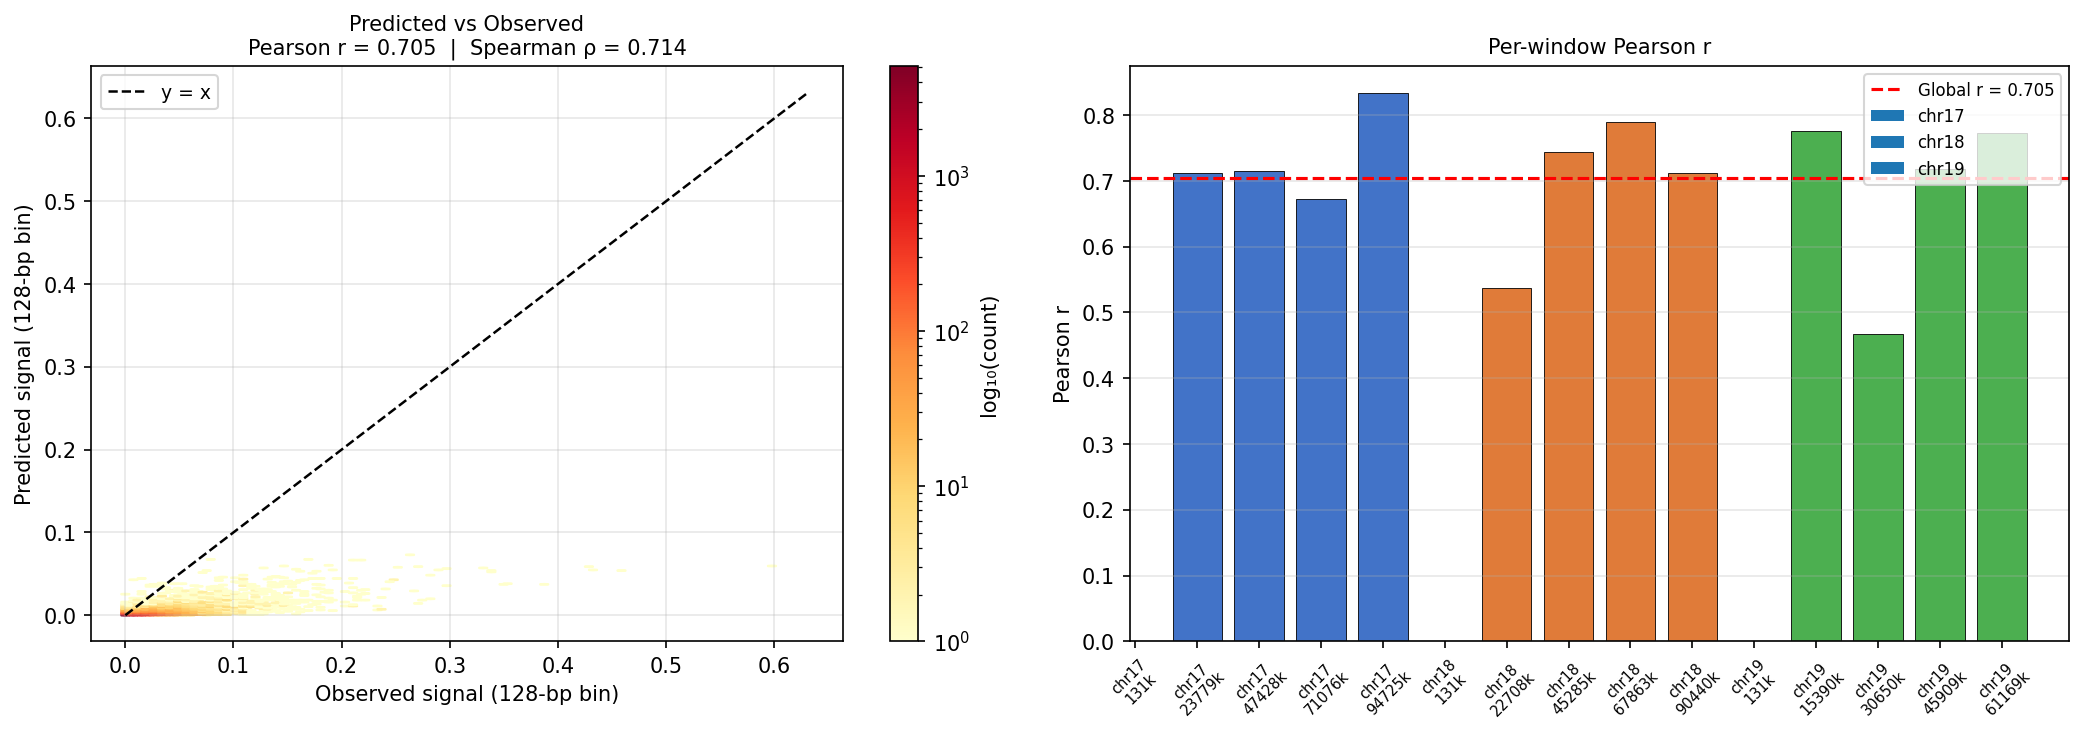


── Predicted vs Observed signal tracks ──


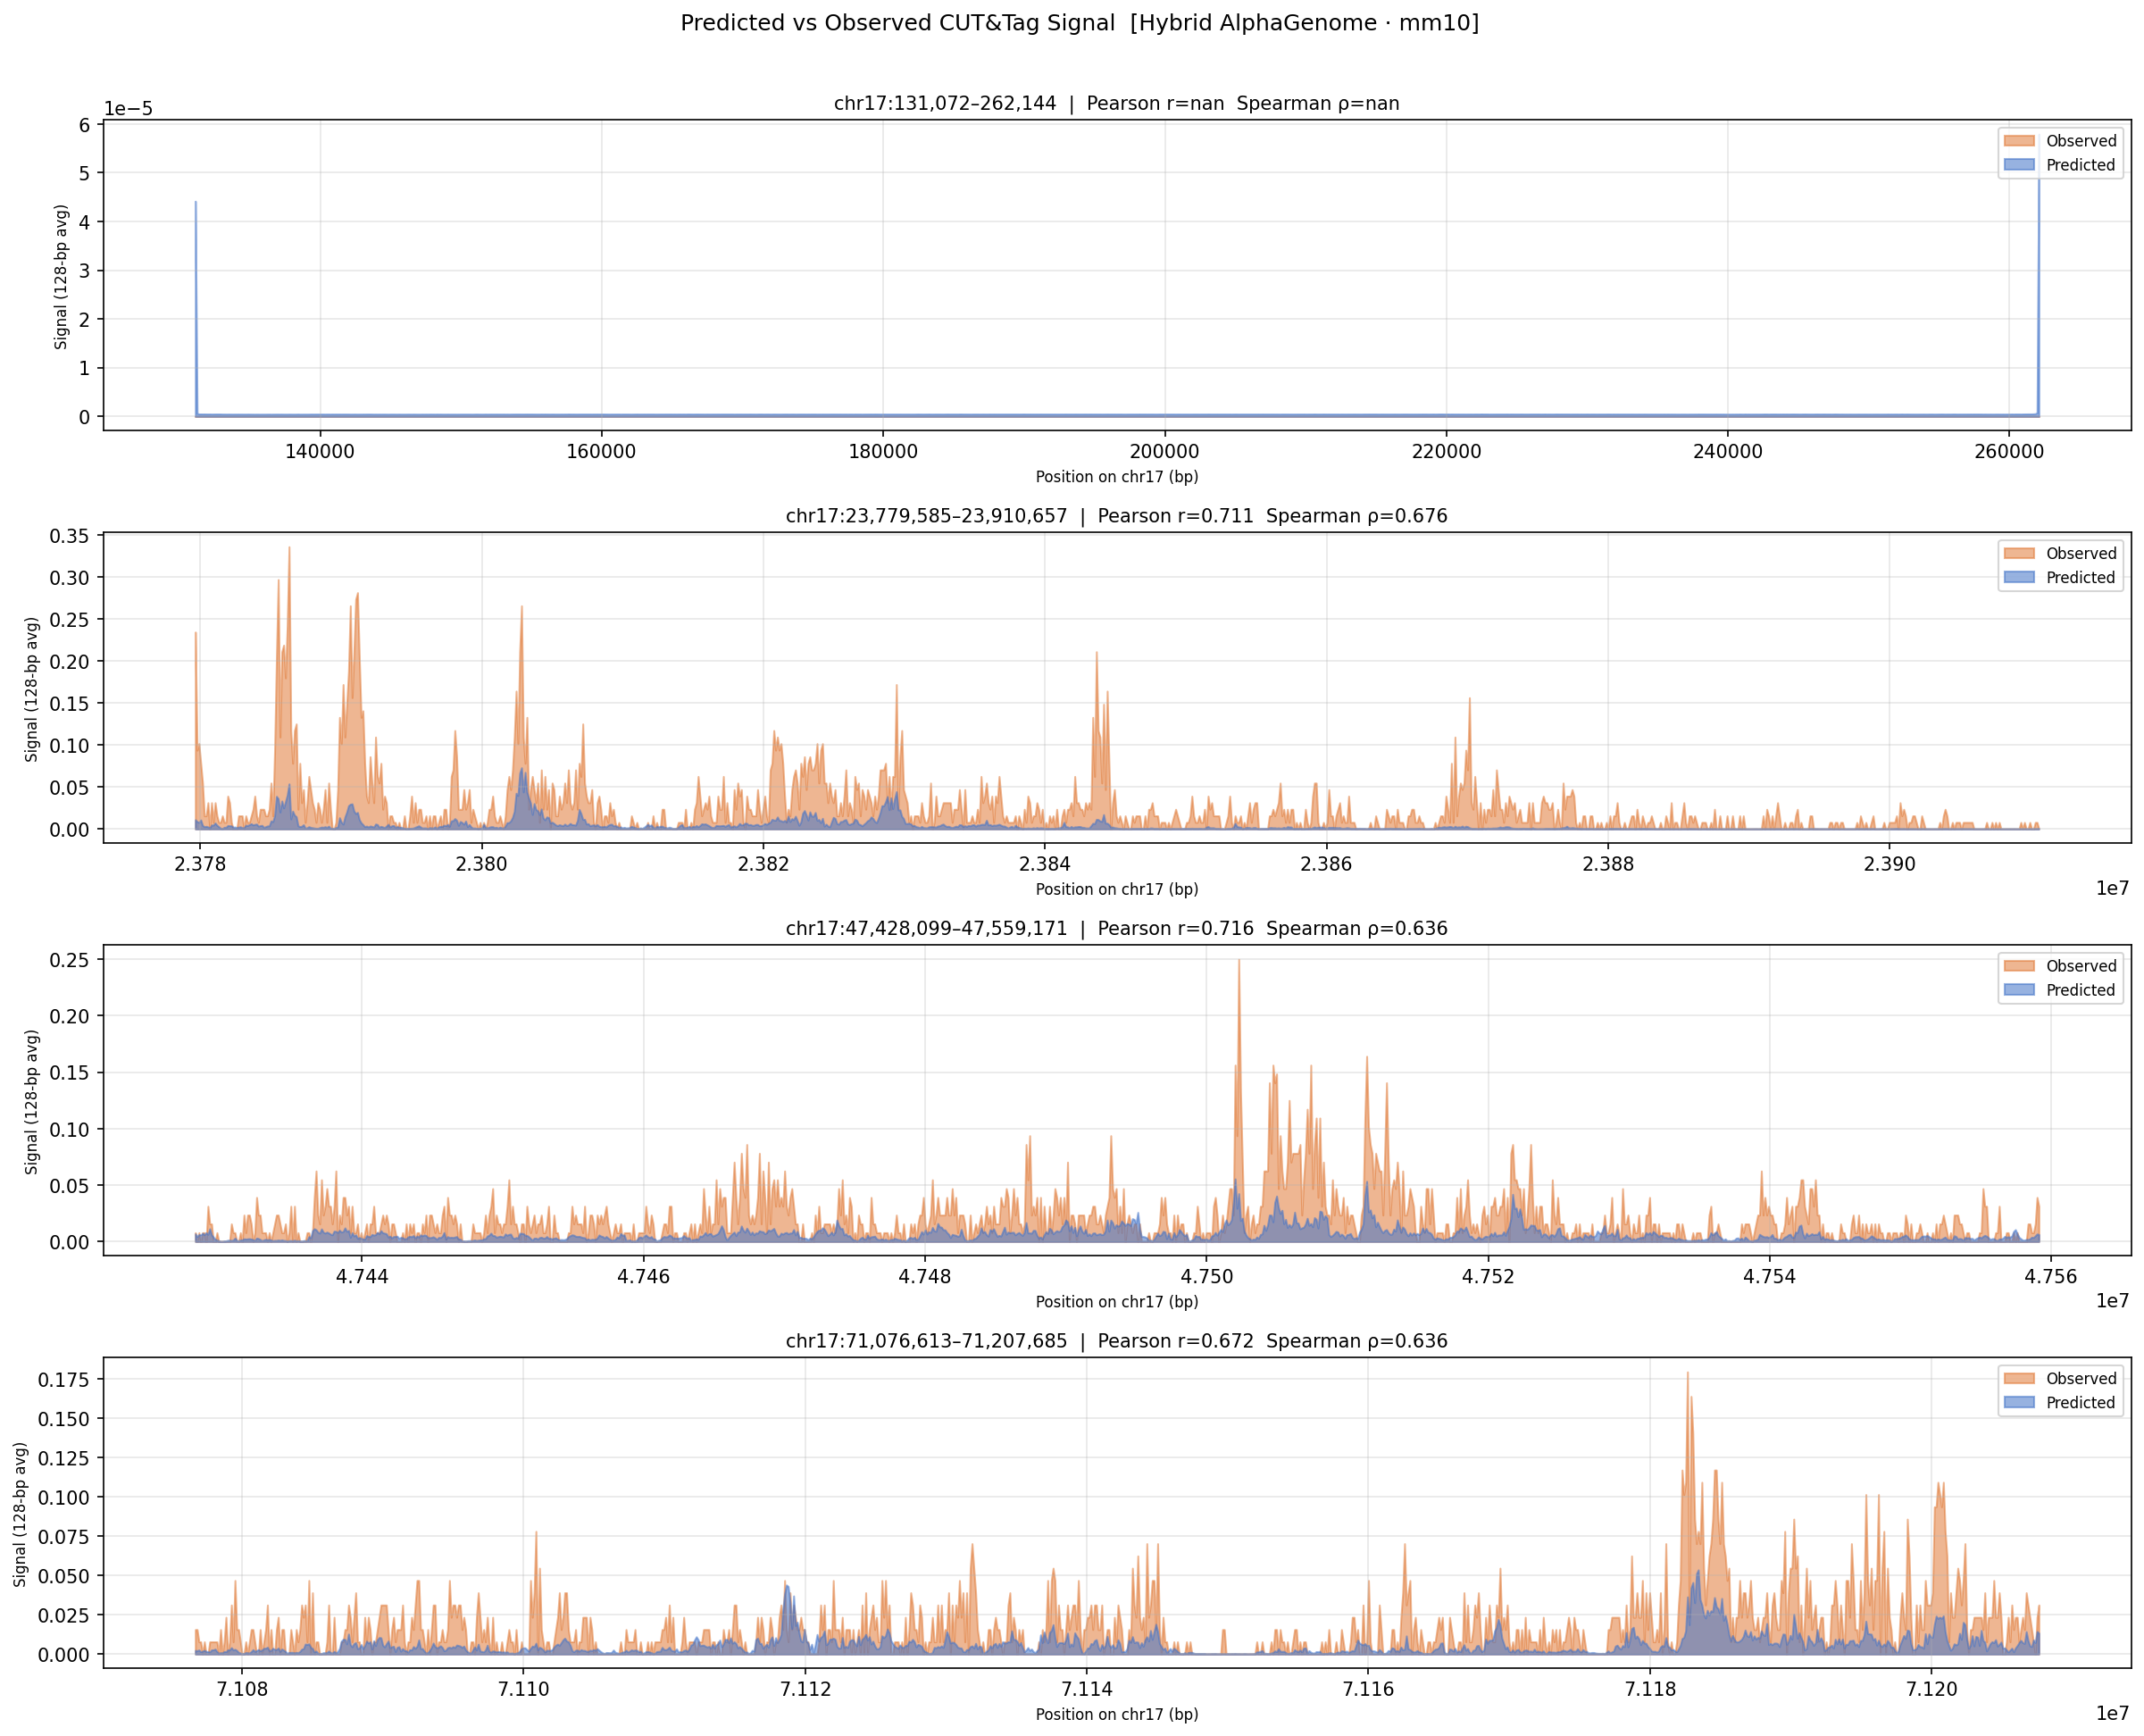


── Top peak-signal windows ──


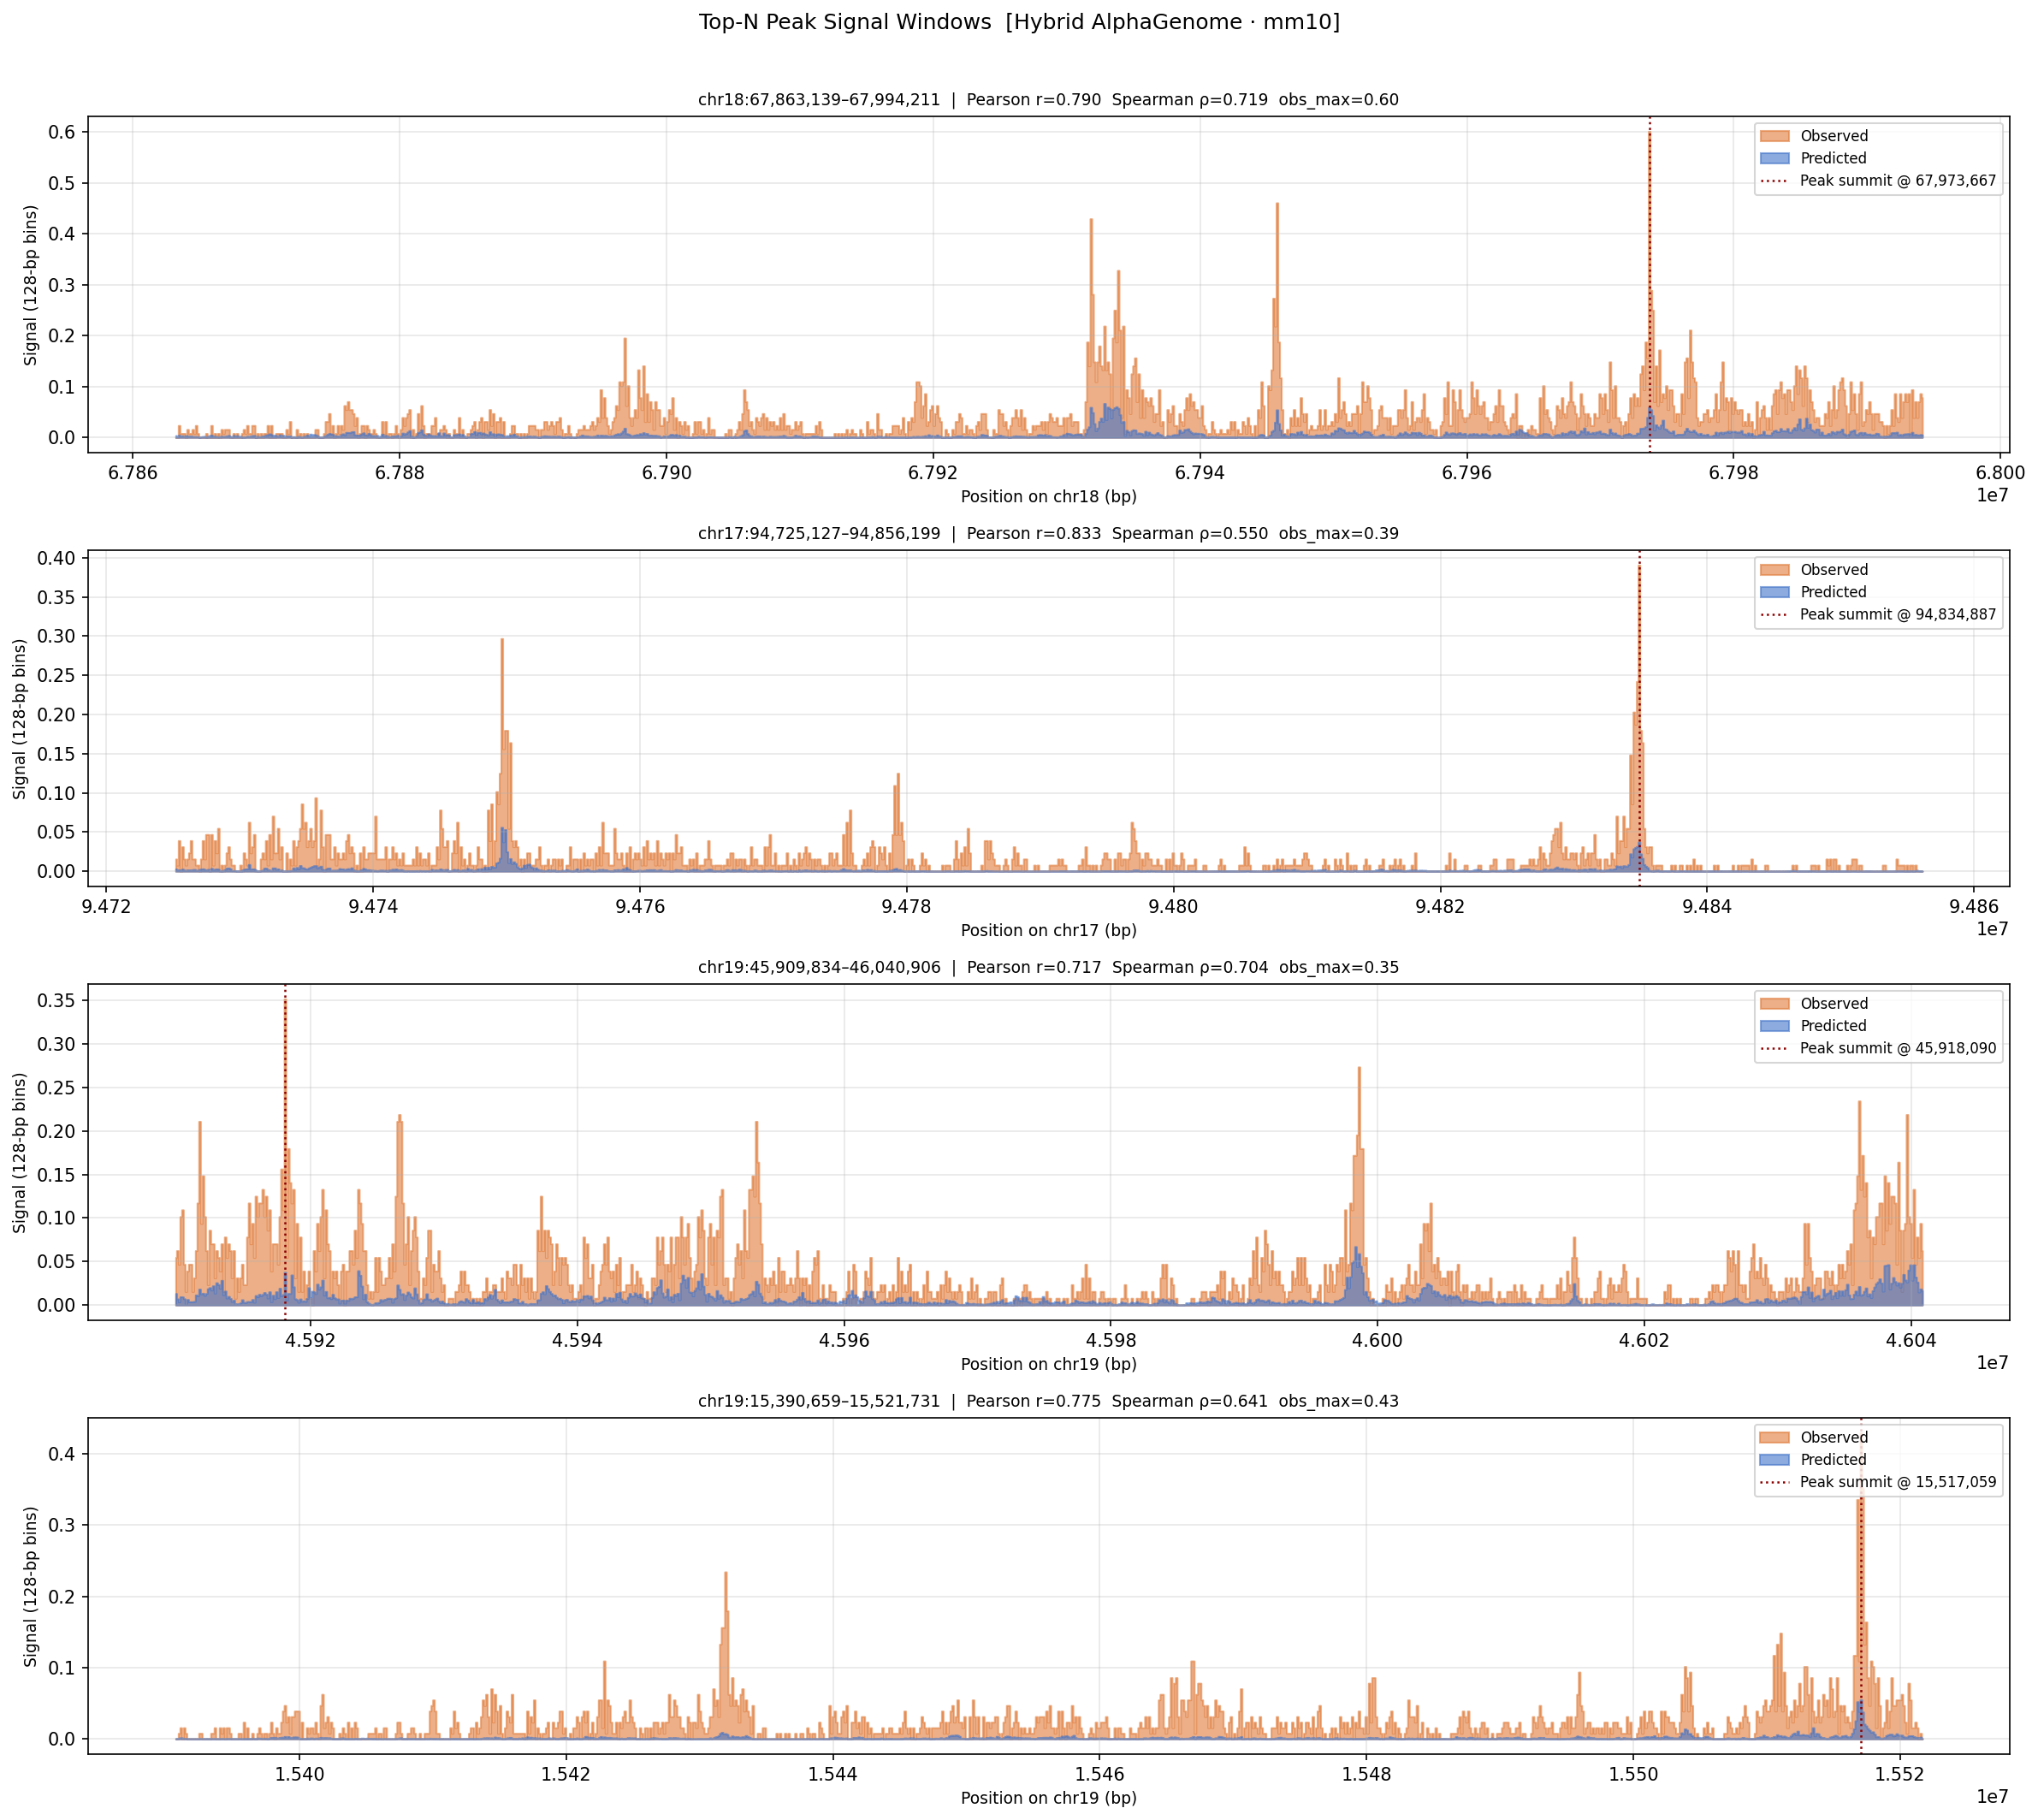


── Training loss curve ──


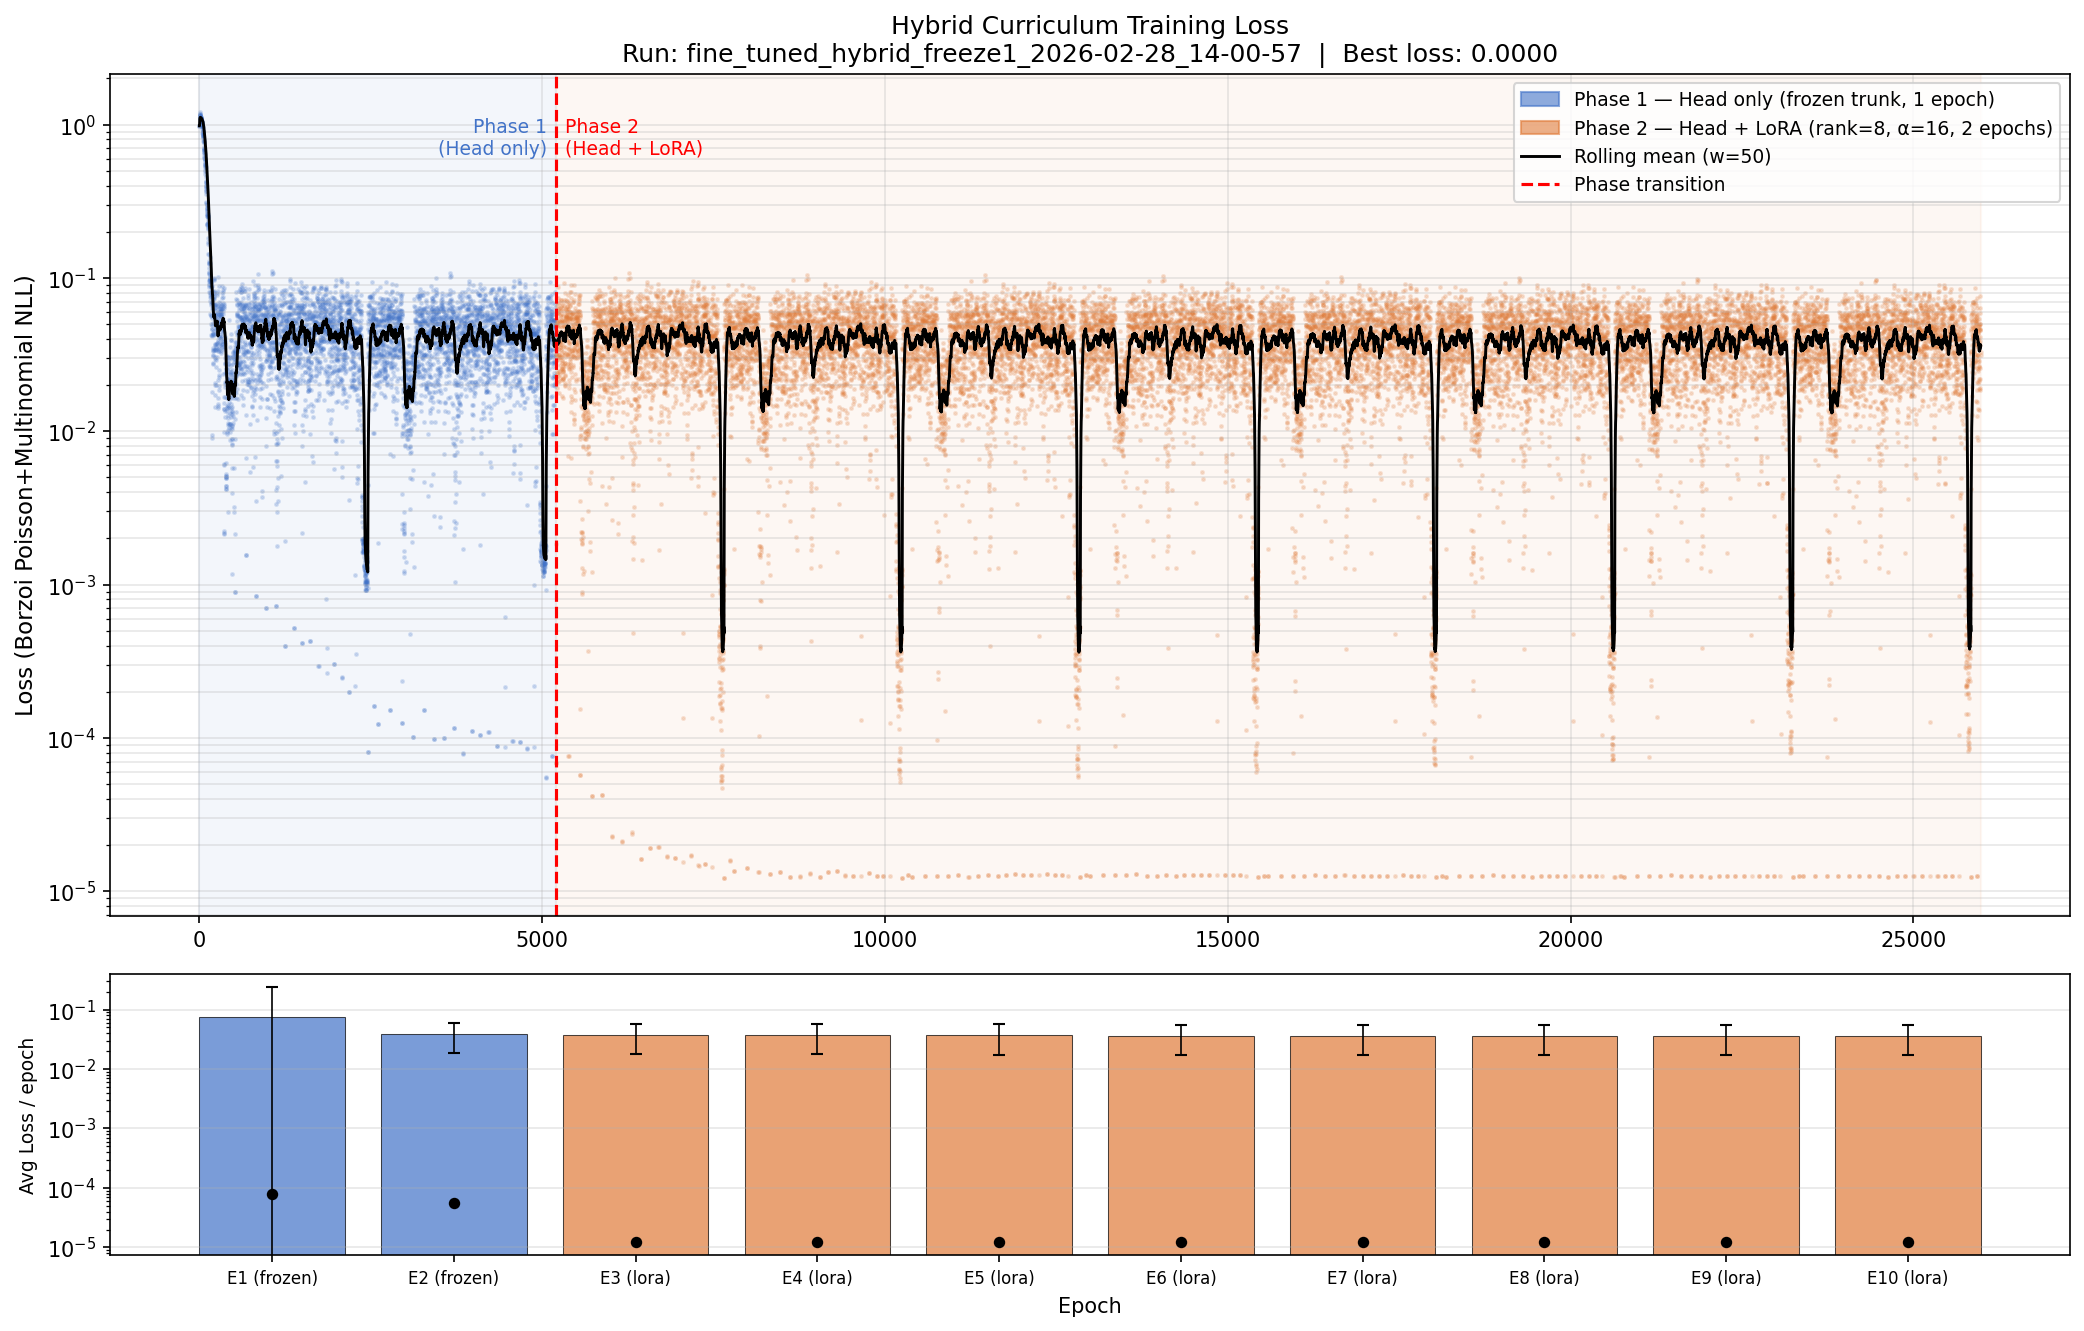

In [8]:
from IPython.display import Image, display
import os, pandas as pd

# ── Correlation metrics table ───────────────────────────────────────────────
metrics_csv = os.path.join(RUN_DIR, 'eval_metrics.csv')
if os.path.exists(metrics_csv):
    mdf = pd.read_csv(metrics_csv)
    print("eval_metrics.csv")
    display(mdf.style.format({'pearson_r': '{:.4f}', 'spearman_r': '{:.4f}',
                              'mse': '{:.4f}', 'mae': '{:.4f}'}))
    print(f"\nMean Pearson r  : {mdf['pearson_r'].mean():.4f}")
    print(f"Mean Spearman ρ : {mdf['spearman_r'].mean():.4f}")
else:
    print(f"eval_metrics.csv not found — run the script first:\n  {metrics_csv}")

# ── Plots ───────────────────────────────────────────────────────────────────
for fname, title in [
    ('eval_correlation.png',    'Scatter + per-window Pearson r'),
    ('pred_vs_obs_tracks.png',  'Predicted vs Observed signal tracks'),
    ('eval_peak_tracks.png',    'Top peak-signal windows'),
    ('training_curve.png',      'Training loss curve'),
]:
    path = os.path.join(RUN_DIR, fname)
    if os.path.exists(path):
        print(f"\n── {title} ──")
        display(Image(path, width=900))
    else:
        print(f"[missing] {fname}")

---
## Summary

| Step | Where |
|------|-------|
| Training curves (sections 3–5) | Notebook — fast, no JAX inference |
| Model loading (section 6) | Notebook — orbax restore, no inference |
| Inference + evaluation | **`scripts/evaluate.py`** — terminal, streamed output |
| View results (section 8) | Notebook — loads saved PNGs + CSV |

**Run the evaluation script:**
```bash
CUDA_VISIBLE_DEVICES=0 conda run -n alphagenome \
    python scripts/evaluate.py \
    --run-dir checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59
```

**Output files** in `checkpoints/fine_tuned_hybrid_freeze2_2026-02-28_16-26-59/`:

| File | Contents |
|------|----------|
| `training_curve.png` | Phase 1 + 2 loss curves (2 frozen + 8 LoRA epochs) |
| `per_epoch_curves.png` | Per-epoch zoom (10 panels) |
| `eval_metrics.csv` | Pearson r / Spearman ρ / MSE / MAE per window |
| `pred_vs_obs_tracks.png` | Signal track overlay |
| `eval_correlation.png` | Hex scatter + per-window bar |
| `eval_peak_tracks.png` | Top-N high-signal windows |